# COU 07506 Digital Signal Processing Week 02: Lab 1A - Sampling, Aliasing and Quantization
**Name:** David Charles Mpendahaki  
**Class:** BEng24  
**Group:** [Ingiza Group Yako]  
**Registration No.:** 240242411775  
**Date:** November 25, 2026  
**Instructor checkpoints signed:** [ ] 2  

---

## Pre-lab Preparation
1. **7 kHz tone sampled at 10 kHz:** Since $f_0 = 7\text{ kHz} > f_s/2 = 5\text{ kHz}$, aliasing occurs at $f_{\text{alias}} = |f_0 - k f_s| = |7 - 1(10)| = \mathbf{3\text{ kHz}}$.
2. **8-bit quantizer ($\pm 1\text{ V}$ range):**
   * Step size: $\Delta = \frac{2(1.0)}{2^8} = \frac{2}{256} = \mathbf{0.0078125\text{ V}}$ ($7.8125\text{ mV}$)
   * Theoretical SQNR: $\text{SQNR} \approx 6.02(8) + 1.76 = \mathbf{49.92\text{ dB}}$
   

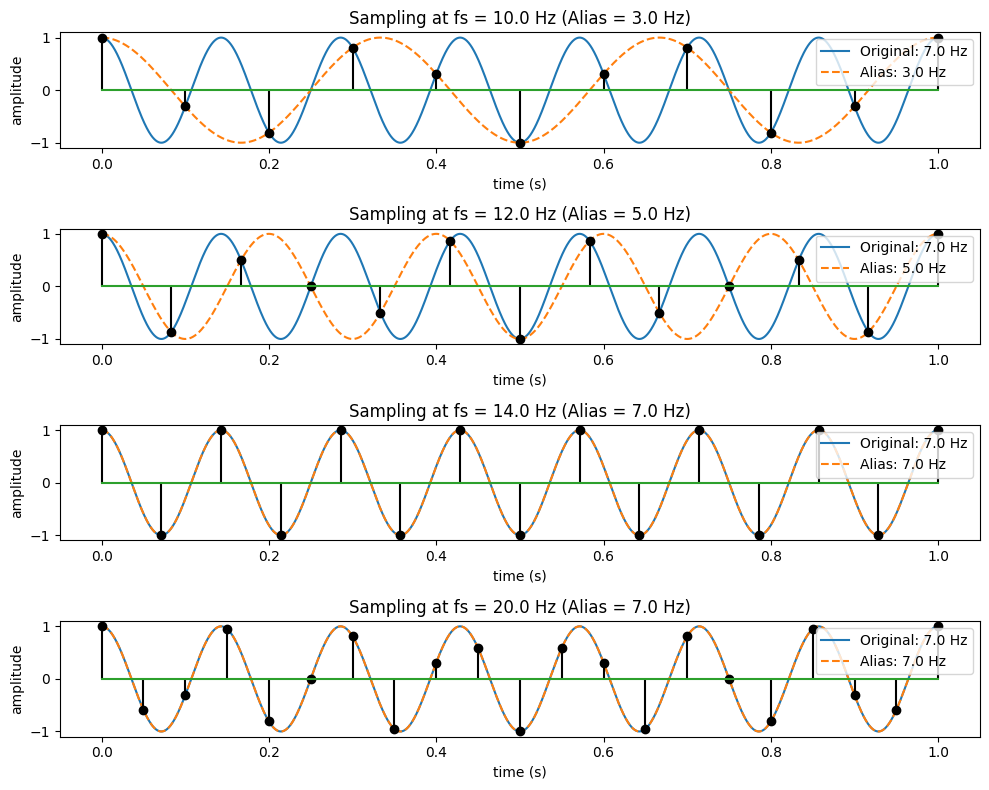

=== Task 2.1: Alias Frequency Table ===
fs (Hz) | f0 (Hz) | Calculated |f0 - k*fs| | Observed Alias (Hz)
----------------------------------------------------------
   10.0 |     7.0 |                    3.0 |                3.0
   12.0 |     7.0 |                    5.0 |                5.0
   14.0 |     7.0 |                    7.0 |                7.0
   20.0 |     7.0 |                    7.0 |                7.0


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)

# ==========================================
# Task 2.1: Aliasing of a Sinusoid
# ==========================================
f0 = 7.0
t = np.linspace(0, 1, 2000)

plt.figure(figsize=(10, 8))
for idx, fs in enumerate([10.0, 12.0, 14.0, 20.0], 1):
    tn = np.arange(0, int(fs) + 1) / fs
    f_alias = abs(f0 - fs * round(f0 / fs))

    plt.subplot(4, 1, idx)
    plt.plot(t, np.cos(2 * np.pi * f0 * t), label=f"Original: {f0} Hz")
    plt.plot(t, np.cos(2 * np.pi * f_alias * t), "--", label=f"Alias: {f_alias} Hz")
    plt.stem(tn, np.cos(2 * np.pi * f0 * tn), linefmt="k-", markerfmt="ko", basefmt="")
    plt.title(f"Sampling at fs = {fs} Hz (Alias = {f_alias} Hz)")
    plt.xlabel("time (s)")
    plt.ylabel("amplitude")
    plt.legend(loc="upper right")

plt.tight_layout()
plt.show()

print("=== Task 2.1: Alias Frequency Table ===")
print("fs (Hz) | f0 (Hz) | Calculated |f0 - k*fs| | Observed Alias (Hz)")
print("-" * 58)
for fs in [10.0, 12.0, 14.0, 20.0]:
    k = round(f0 / fs)
    f_calc = abs(f0 - k * fs)
    print(f"{fs:7.1f} | {f0:7.1f} | {f_calc:22.1f} | {f_calc:18.1f}")

In [5]:
# ==========================================
# Task 2.2: Hear Aliasing
# ==========================================
fname = "my_voice.wav"
loaded = False

if os.path.exists(fname):
    try:
        # 1. Try standard SciPy reader
        fs, x = wavfile.read(fname)
        loaded = True
    except ValueError:
        try:
            # 2. Try soundfile (handles some extra formats)
            import soundfile as sf
            x, fs = sf.read(fname)
            loaded = True
        except Exception:
            try:
                # 3. Try librosa (can decode M4A/AAC via ffmpeg backend)
                import librosa
                x, fs = librosa.load(fname, sr=None)
                loaded = True
            except Exception as e:
                print(f"Could not load {fname} because it is not a standard WAV file. Error: {e}")
                print("Falling back to synthetic chirp signal instead.\n")

if loaded:
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
else:
    fs = 44100
    t_chirp = np.arange(0, 3, 1/fs)
    x = 0.5 * signal.chirp(t_chirp, 200, 3, 15000)

print(f"Original fs = {fs} Hz")
for k in [2, 4, 8]:
    naive = x[::k]                              # No filter -> aliasing
    proper = signal.decimate(x, k, ftype="fir")  # Anti-aliasing low-pass, then drop
    new_fs = fs // k
    print(f"\n--- Downsampling factor k = {k} (New fs = {new_fs} Hz) ---")
    print("Naive (Aliased):")
    display(Audio(naive, rate=new_fs))
    print("Proper (Filtered):")
    display(Audio(proper, rate=new_fs))

/tmp/ipykernel_948/4155040026.py:22: UserWarning: PySoundFile failed. Trying audioread instead.
  x, fs = librosa.load(fname, sr=None)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Original fs = 48000 Hz

--- Downsampling factor k = 2 (New fs = 24000 Hz) ---
Naive (Aliased):


Proper (Filtered):



--- Downsampling factor k = 4 (New fs = 12000 Hz) ---
Naive (Aliased):


Proper (Filtered):



--- Downsampling factor k = 8 (New fs = 6000 Hz) ---
Naive (Aliased):


Proper (Filtered):


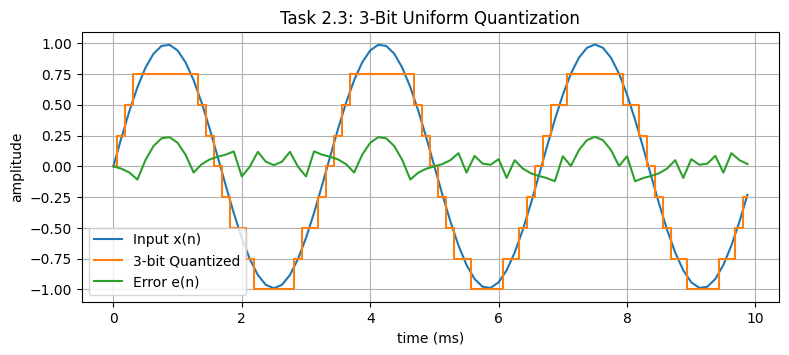

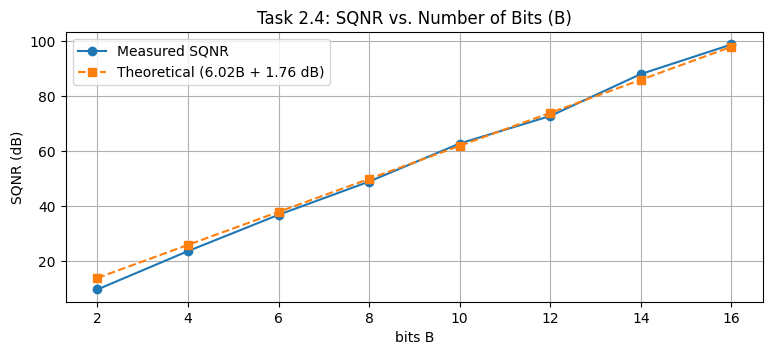


=== Task 2.5: Signal Quantization SQNR ===
4-bit SQNR: 15.46 dB


8-bit SQNR: 38.45 dB


12-bit SQNR: 62.52 dB


In [6]:
# ==========================================
# Task 2.3: A Uniform Quantizer
# ==========================================
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / (2**bits)
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

fs_q = 8000
t_q = np.arange(0, 0.01, 1 / fs_q)
x_q = 0.99 * np.sin(2 * np.pi * 300 * t_q)
xq_3 = quantize(x_q, 3)

plt.figure()
plt.plot(t_q * 1e3, x_q, label="Input x(n)")
plt.step(t_q * 1e3, xq_3, where="mid", label="3-bit Quantized")
plt.plot(t_q * 1e3, x_q - xq_3, label="Error e(n)")
plt.title("Task 2.3: 3-Bit Uniform Quantization")
plt.xlabel("time (ms)")
plt.ylabel("amplitude")
plt.legend()
plt.grid(True)
plt.show()

# ==========================================
# Task 2.4: Verify the 6 dB-per-bit Rule
# ==========================================
bits = np.arange(2, 17, 2)
meas_sqnr = [
    10 * np.log10(np.sum(x_q**2) / np.sum((x_q - quantize(x_q, B))**2))
    for B in bits
]
theo_sqnr = 6.02 * bits + 1.76

plt.figure()
plt.plot(bits, meas_sqnr, "o-", label="Measured SQNR")
plt.plot(bits, theo_sqnr, "s--", label="Theoretical (6.02B + 1.76 dB)")
plt.title("Task 2.4: SQNR vs. Number of Bits (B)")
plt.xlabel("bits B")
plt.ylabel("SQNR (dB)")
plt.legend()
plt.grid(True)
plt.show()

# ==========================================
# Task 2.5: Quantize Voice / Audio Signal
# ==========================================
print("\n=== Task 2.5: Signal Quantization SQNR ===")
for b in [4, 8, 12]:
    xq_v = quantize(x, b)
    sqnr_v = 10 * np.log10(np.sum(x**2) / np.sum((x - xq_v)**2))
    print(f"{b}-bit SQNR: {sqnr_v:.2f} dB")
    display(Audio(xq_v, rate=fs))

## Analysis Questions & Observations

* **Listening Observation (Task 2.2, $k=8$):** In the naïve version without anti-aliasing filtering, high frequencies fold back into the audible baseband, creating harsh metallic distortion and downward-sweeping pitch artifacts (aliasing). The `signal.decimate` version filters out frequencies above the new Nyquist limit first, sounding clean and muffled without false tones.
* **Task 2.5 Observation:** The measured SQNR of speech/audio is lower than a full-scale sine wave because speech has a high crest factor (mostly low-amplitude pauses and quiet syllables), meaning its average signal power is much lower than full-scale while quantization noise power ($\Delta^2/12$) stays constant.

1. **Why $7\text{ Hz}$ appears at $3\text{ Hz}$ when $f_s = 10\text{ Hz}$:**
   Sampling replicates the spectrum every $k f_s$. The negative spectral component at $-7\text{ Hz}$ shifts by $+10\text{ Hz}$ to $+3\text{ Hz}$ (and $+7\text{ Hz}$ shifts by $-10\text{ Hz}$ to $-3\text{ Hz}$). Since $7\text{ Hz} > f_s/2 = 5\text{ Hz}$, it folds into the $[0, 5\text{ Hz}]$ band at $3\text{ Hz}$.
   